<a href="https://colab.research.google.com/github/Aldiss1/MPPM_Aldi/blob/main/JS11/JS11-Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab — CNN: CIFAR-10 (> 80%) dan MNIST

**Mata Kuliah:** RTI235004 — Pembelajaran Mesin (Polinema)  
**Modul:** JS11 — Convolutional Neural Network  
**Nama:** Aldi Surya Saputra

## Instruksi Tugas

* Modifikasi model CNN pada praktikum 2 sehingga didapatkan akurasi testing lebih dari 80%.
* Buatlah model CNN untuk klasifikasi dataset MNIST.



## Bagian A — CIFAR-10
### Langkah 1 - Import Library dan Set Seed

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, callbacks

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


### Langkah 2 - Load Dataset CIFAR-10

In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalisasi nilai piksel ke rentang 0-1
train_images, test_images = train_images / 255.0, test_images / 255.0

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print('train_images :', train_images.shape, train_images.dtype)
print('train_labels :', train_labels.shape)
print('test_images  :', test_images.shape)
print('test_labels  :', test_labels.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 15s 0us/step
train_images : (50000, 32, 32, 3) float64
train_labels : (50000, 1)
test_images  : (10000, 32, 32, 3)
test_labels  : (10000, 1)


### Langkah 3 - Verifikasi Data

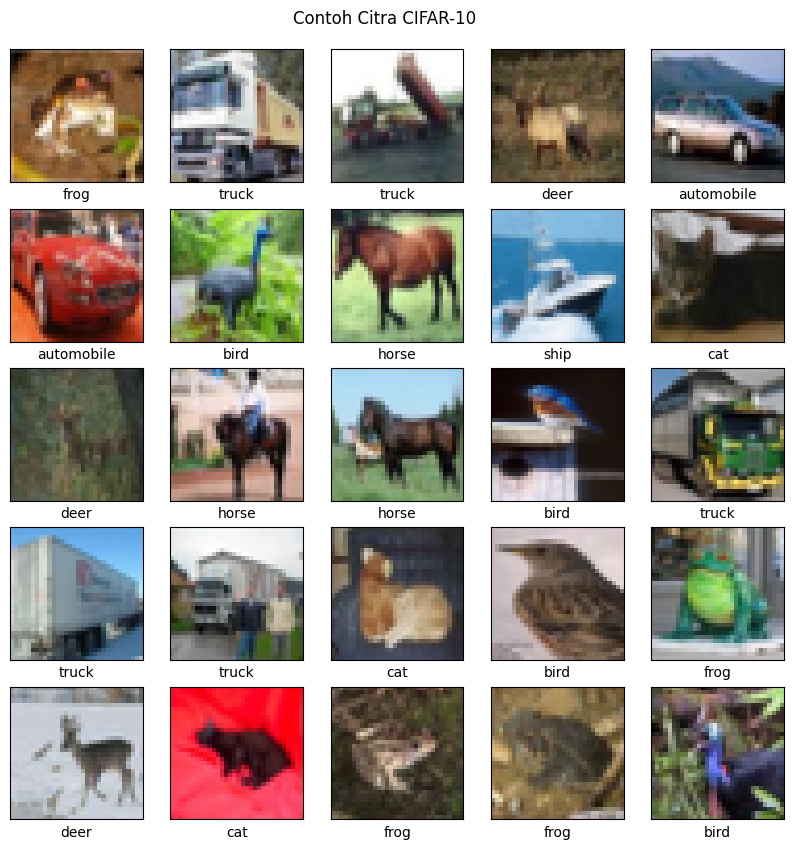

In [3]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])
plt.suptitle('Contoh Citra CIFAR-10', y=0.92)
plt.show()

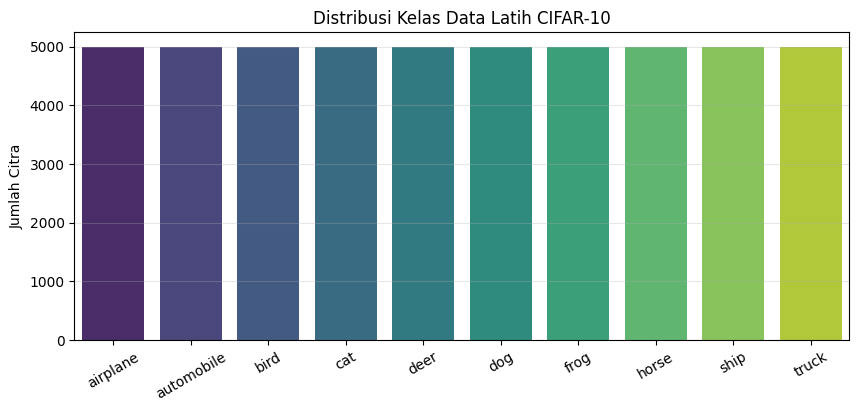

Total data latih: 50000 | tiap kelas: 5000 - 5000


In [4]:
jumlah = np.bincount(train_labels.flatten(), minlength=10)

plt.figure(figsize=(10, 4))
sns.barplot(x=class_names, y=jumlah, hue=class_names, palette='viridis', legend=False)
plt.title('Distribusi Kelas Data Latih CIFAR-10')
plt.ylabel('Jumlah Citra')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.show()

print('Total data latih:', jumlah.sum(), '| tiap kelas:', jumlah.min(), '-', jumlah.max())

### Langkah 4 - Buat Model CNN yang Dimodifikasi

Perubahan dibanding Lab 2 ditandai pada komentar kode.

In [5]:
model = models.Sequential(name='CNN_CIFAR10_Improved')
model.add(layers.Input(shape=(32, 32, 3)))

# --- Data augmentation (modifikasi) ---
model.add(layers.RandomCrop(32, 32))
model.add(layers.RandomFlip('horizontal'))

# --- Blok konvolusi 1: 2x Conv 32 filter ---
model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Dropout(0.2))

# --- Blok konvolusi 2: 2x Conv 64 filter ---
model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Dropout(0.3))

# --- Blok konvolusi 3: 2x Conv 128 filter ---
model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Dropout(0.4))

# --- Fully connected ---
model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))
model.add(layers.Dense(10, activation='softmax'))

model.summary()

Model: "CNN_CIFAR10_Improved"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_crop (RandomCrop)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,54

 Total params: 816,938 (3.12 MB)

 Trainable params: 815,530 (3.11 MB)

 Non-trainable params: 1,408 (5.50 KB)

### Langkah 5 - Compile Model

In [6]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

### Langkah 6 - Fit Model

In [7]:
cb_early = callbacks.EarlyStopping(monitor='val_accuracy', patience=8,
                                    restore_best_weights=True, mode='max')
cb_lr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                    patience=3, min_lr=1e-5, verbose=1)

history = model.fit(train_images, train_labels,
                    epochs=40, batch_size=128,
                    validation_data=(test_images, test_labels),
                    callbacks=[cb_early, cb_lr])

Epoch 1/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 276s 696ms/step - accuracy: 0.4313 - loss: 1.7040 - val_accuracy: 0.2313 - val_loss: 2.6835 - learning_rate: 0.0010
Epoch 2/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 332s 722ms/step - accuracy: 0.5973 - loss: 1.1284 - val_accuracy: 0.6703 - val_loss: 0.9183 - learning_rate: 0.0010
Epoch 3/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 271s 694ms/step - accuracy: 0.6666 - loss: 0.9429 - val_accuracy: 0.7159 - val_loss: 0.8062 - learning_rate: 0.0010
Epoch 4/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 324s 700ms/step - accuracy: 0.7064 - loss: 0.8329 - val_accuracy: 0.7049 - val_loss: 0.8457 - learning_rate: 0.0010
Epoch 5/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 283s 725ms/step - accuracy: 0.7335 - loss: 0.7597 - val_accuracy: 0.7629 - val_loss: 0.6846 - learning_rate: 0.0010
Epoch 6/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 322s 724ms/step - accuracy: 0.7550 - loss: 0.7034 - val_accuracy: 0.7281 - val_loss: 0.8305 - learning_rate: 0.0010
Epoch 7/40
391/391 ━━━━━━━━━━━━━━━━━━━━ 275s 702ms/step - accura

### Langkah 7 - Visualisasi Proses Training

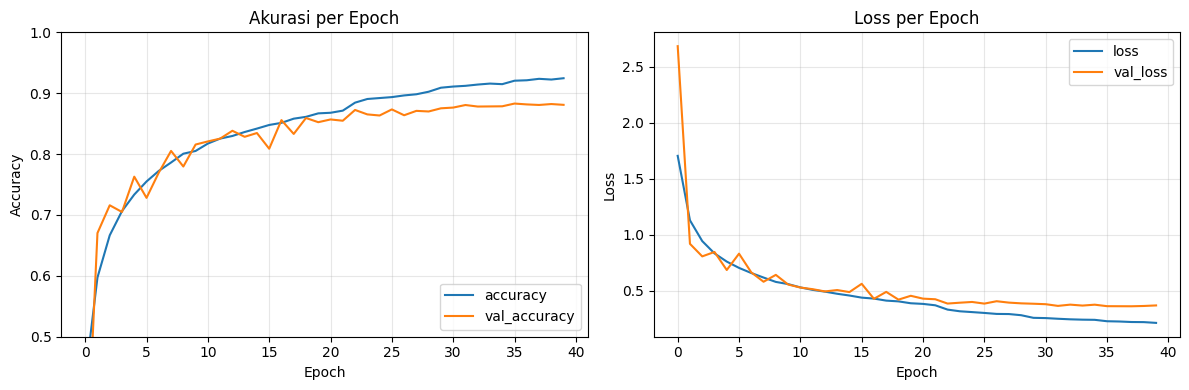

In [8]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.ylim([0.5, 1]); plt.legend(loc='lower right'); plt.grid(alpha=0.3)
plt.title('Akurasi per Epoch')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.legend(loc='upper right'); plt.grid(alpha=0.3)
plt.title('Loss per Epoch')
plt.tight_layout()
plt.show()

### Langkah 8 - Evaluasi Model

In [9]:
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print('Test loss     :', test_loss)
print('Test accuracy :', test_acc)

313/313 - 12s - 40ms/step - accuracy: 0.8830 - loss: 0.3616
Test loss     : 0.3615953028202057
Test accuracy : 0.8830000162124634


In [10]:
y_prob = model.predict(test_images)
y_pred = np.argmax(y_prob, axis=1)
y_true = test_labels.flatten()

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step
              precision    recall  f1-score   support

    airplane     0.8936    0.8900    0.8918      1000
  automobile     0.9536    0.9250    0.9391      1000
        bird     0.8447    0.8320    0.8383      1000
         cat     0.7976    0.7290    0.7618      1000
        deer     0.8487    0.9090    0.8778      1000
         dog     0.8493    0.8170    0.8328      1000
        frog     0.8721    0.9410    0.9052      1000
       horse     0.9428    0.9060    0.9240      1000
        ship     0.9263    0.9300    0.9281      1000
       truck     0.8989    0.9510    0.9242      1000

    accuracy                         0.8830     10000
   macro avg     0.8827    0.8830    0.8823     10000
weighted avg     0.8827    0.8830    0.8823     10000



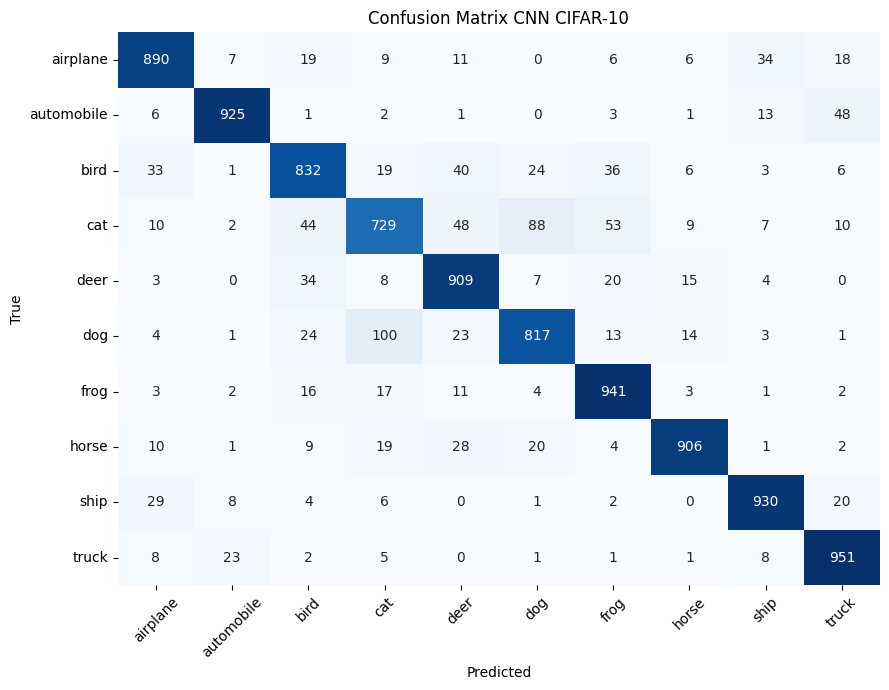

In [11]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion Matrix CNN CIFAR-10')
plt.xticks(rotation=45); plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

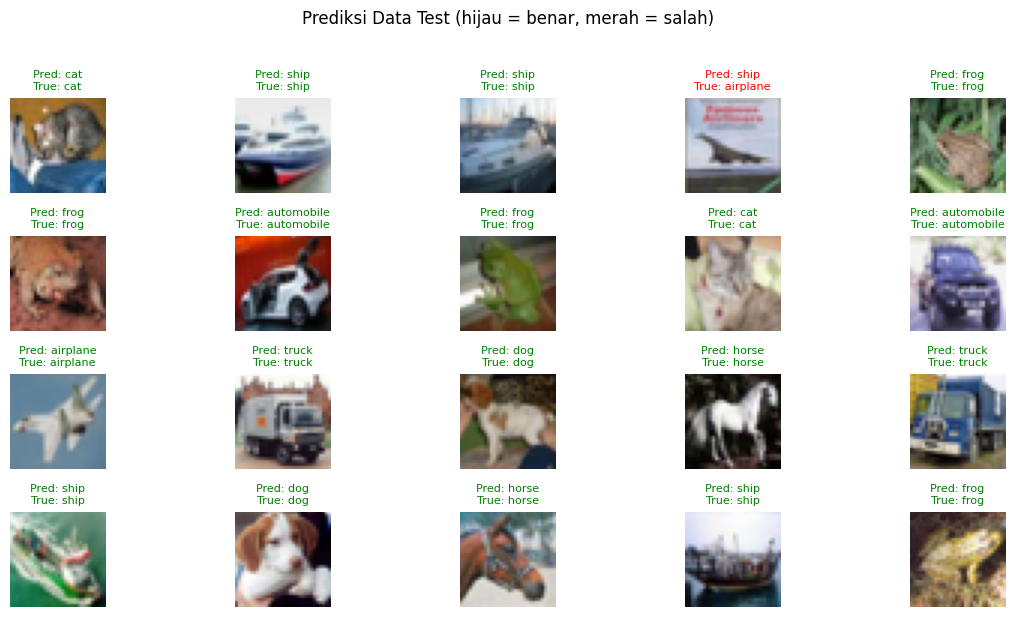

In [12]:
plt.figure(figsize=(12, 6))
for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(test_images[i])
    warna = 'green' if y_pred[i] == y_true[i] else 'red'
    plt.title(f'Pred: {class_names[y_pred[i]]}\nTrue: {class_names[y_true[i]]}',
              fontsize=8, color=warna)
    plt.axis('off')
plt.suptitle('Prediksi Data Test (hijau = benar, merah = salah)', y=1.02)
plt.tight_layout()
plt.show()

### Langkah 9 - Cetak Hasil Akurasi

In [13]:
print(f'Akurasi test CIFAR-10: {test_acc:.4f} ({test_acc*100:.2f}%)')
print('Target > 80% :', 'TERCAPAI' if test_acc > 0.8 else 'BELUM TERCAPAI')

Akurasi test CIFAR-10: 0.8830 (88.30%)
Target > 80% : TERCAPAI


## Bagian B — MNIST
### Langkah 1 - Load Dataset MNIST

In [14]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_test = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

print('x_train:', x_train.shape)
print('y_train:', y_train.shape)
print('x_test :', x_test.shape)
print('y_test :', y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train: (60000, 28, 28, 1)
y_train: (60000,)
x_test : (10000, 28, 28, 1)
y_test : (10000,)


### Langkah 2 - Verifikasi Data

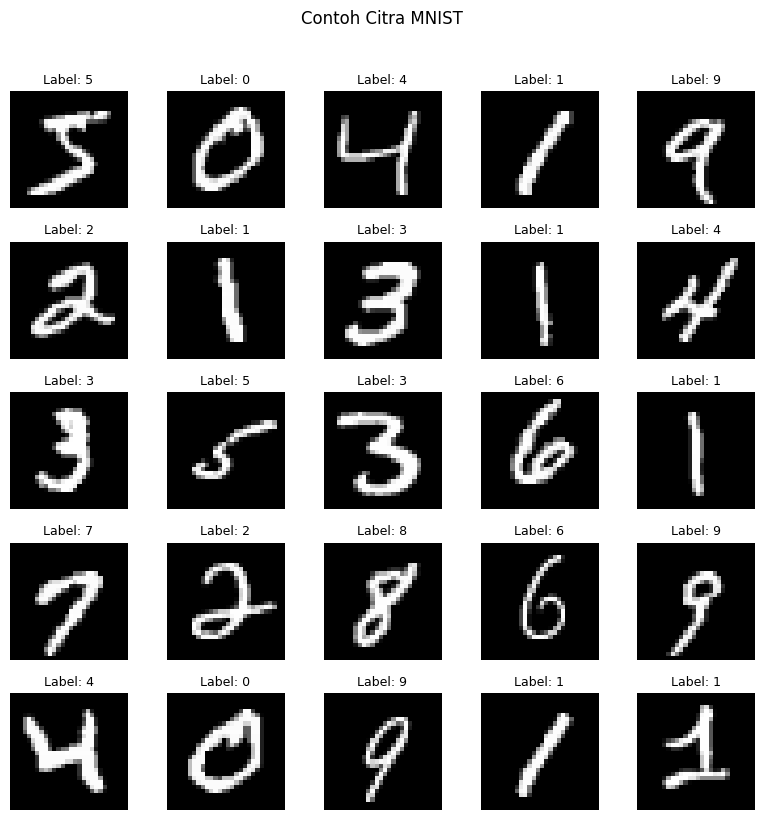

In [15]:
plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title(f'Label: {y_train[i]}', fontsize=9)
    plt.axis('off')
plt.suptitle('Contoh Citra MNIST', y=1.02)
plt.tight_layout()
plt.show()

### Langkah 3 - Buat Model CNN

In [16]:
mnist_model = models.Sequential(name='CNN_MNIST')
mnist_model.add(layers.Input(shape=(28, 28, 1)))

mnist_model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
mnist_model.add(layers.BatchNormalization())
mnist_model.add(layers.MaxPooling2D((2, 2)))
mnist_model.add(layers.Dropout(0.25))

mnist_model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
mnist_model.add(layers.BatchNormalization())
mnist_model.add(layers.MaxPooling2D((2, 2)))
mnist_model.add(layers.Dropout(0.25))

mnist_model.add(layers.Flatten())
mnist_model.add(layers.Dense(128, activation='relu'))
mnist_model.add(layers.Dropout(0.5))
mnist_model.add(layers.Dense(10, activation='softmax'))

mnist_model.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])
mnist_model.summary()

Model: "CNN_MNIST"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,026 (1.61 MB)

 Trainable params: 421,834 (1.61 MB)

 Non-trainable params: 192 (768.00 B)

### Langkah 4 - Fit Model

In [17]:
history_mnist = mnist_model.fit(
    x_train, y_train,
    epochs=12, batch_size=128,
    validation_split=0.1,
    callbacks=[callbacks.EarlyStopping(monitor='val_accuracy', patience=3,
                                       restore_best_weights=True, mode='max')]
)

Epoch 1/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 55s 128ms/step - accuracy: 0.8597 - loss: 0.4562 - val_accuracy: 0.8195 - val_loss: 0.5975
Epoch 2/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 53s 126ms/step - accuracy: 0.9530 - loss: 0.1571 - val_accuracy: 0.9897 - val_loss: 0.0405
Epoch 3/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 53s 127ms/step - accuracy: 0.9650 - loss: 0.1189 - val_accuracy: 0.9882 - val_loss: 0.0415
Epoch 4/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 52s 124ms/step - accuracy: 0.9698 - loss: 0.1008 - val_accuracy: 0.9897 - val_loss: 0.0368
Epoch 5/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 123ms/step - accuracy: 0.9751 - loss: 0.0864 - val_accuracy: 0.9918 - val_loss: 0.0330
Epoch 6/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 123ms/step - accuracy: 0.9767 - loss: 0.0776 - val_accuracy: 0.9880 - val_loss: 0.0401
Epoch 7/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 53s 125ms/step - accuracy: 0.9771 - loss: 0.0746 - val_accuracy: 0.9918 - val_loss: 0.0331
Epoch 8/12
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 127ms/step - accuracy: 0.9806 - loss: 0

### Langkah 5 - Evaluasi Model

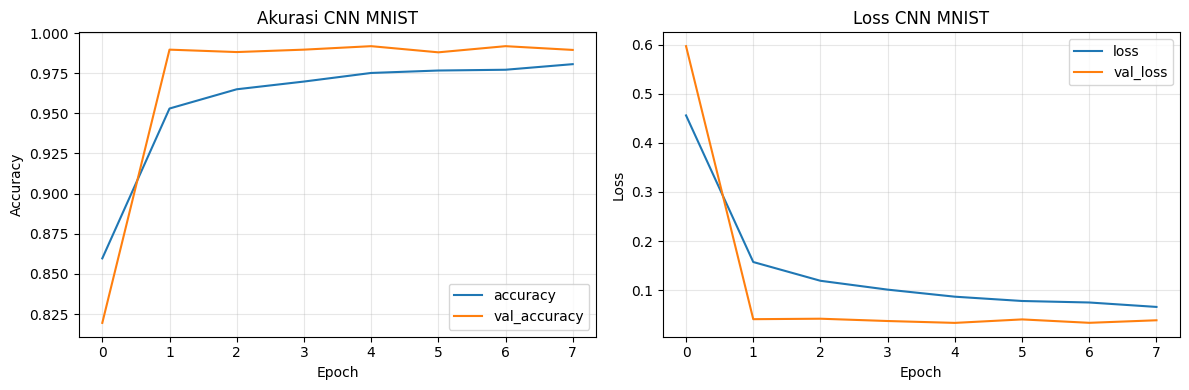

313/313 - 3s - 11ms/step - accuracy: 0.9898 - loss: 0.0340
Test loss     : 0.03400993347167969
Test accuracy : 0.989799976348877


In [18]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_mnist.history['accuracy'], label='accuracy')
plt.plot(history_mnist.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(alpha=0.3)
plt.title('Akurasi CNN MNIST')

plt.subplot(1, 2, 2)
plt.plot(history_mnist.history['loss'], label='loss')
plt.plot(history_mnist.history['val_loss'], label='val_loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(alpha=0.3)
plt.title('Loss CNN MNIST')
plt.tight_layout()
plt.show()

mnist_loss, mnist_acc = mnist_model.evaluate(x_test, y_test, verbose=2)
print('Test loss     :', mnist_loss)
print('Test accuracy :', mnist_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step
              precision    recall  f1-score   support

           0     0.9848    0.9949    0.9898       980
           1     0.9956    0.9974    0.9965      1135
           2     0.9884    0.9932    0.9908      1032
           3     0.9892    0.9960    0.9926      1010
           4     0.9949    0.9878    0.9913       982
           5     0.9855    0.9910    0.9883       892
           6     0.9947    0.9854    0.9900       958
           7     0.9902    0.9854    0.9878      1028
           8     0.9887    0.9887    0.9887       974
           9     0.9850    0.9772    0.9811      1009

    accuracy                         0.9898     10000
   macro avg     0.9897    0.9897    0.9897     10000
weighted avg     0.9898    0.9898    0.9898     10000



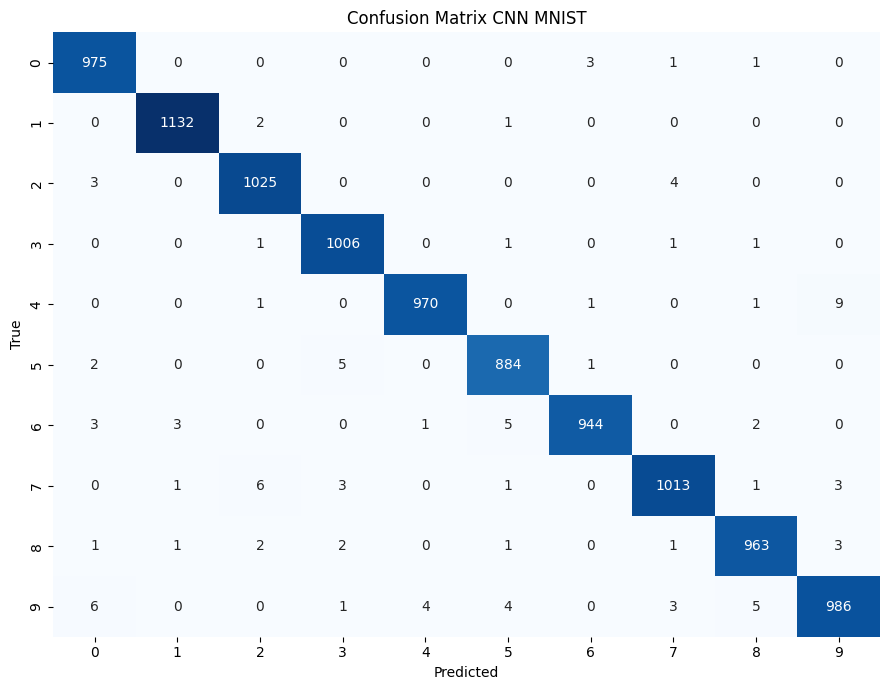

Akurasi test MNIST: 0.9898


In [19]:
y_prob_mnist = mnist_model.predict(x_test)
y_pred_mnist = np.argmax(y_prob_mnist, axis=1)

print(classification_report(y_test, y_pred_mnist, digits=4))

cm_mnist = confusion_matrix(y_test, y_pred_mnist)
plt.figure(figsize=(9, 7))
sns.heatmap(cm_mnist, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion Matrix CNN MNIST')
plt.tight_layout()
plt.show()

print(f'Akurasi test MNIST: {accuracy_score(y_test, y_pred_mnist):.4f}')

### Langkah 6 - Simpan Model

In [20]:
model.save('cnn_cifar10_improved.keras')
mnist_model.save('cnn_mnist.keras')
print('Model disimpan: cnn_cifar10_improved.keras dan cnn_mnist.keras')

Model disimpan: cnn_cifar10_improved.keras dan cnn_mnist.keras
